# Sensibilidade da política fiscal fixa

Este notebook analisa o experimento austríaco de **zero ao dobro da calibração**. A unidade de análise é a configuração fiscal: as dez sementes de cada política medem o ruído da simulação, não criam dez políticas independentes.

Há duas perguntas distintas. Para cada parâmetro, os níveis **0%, 50%, 100%, 150% e 200%** são comparados à política base com as **mesmas sementes**, mudando só esse parâmetro. Para o PIB real, o efeito é **Δ% = 100 × (PIB da política / PIB da base − 1)** em cada semente e trimestre. Os pontos LHS mostram associações marginais em todo o domínio. Correlações e mapas bivariados são triagens descritivas; **não são índices de Sobol nem identificam interações causais**. A política com os quatro parâmetros simultaneamente em zero não faz parte desta amostra.

Execute as células em ordem. `FOCUS_METRIC` escolhe o indicador dos gráficos detalhados. Tabelas e figuras são salvas em `experiments/<EXPERIMENT_NAME>/sensitivity/`.

In [8]:
from pathlib import Path
import tomllib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXPERIMENT_NAME = "austria-scale-0.001-zero-to-double-expanded"
FOCUS_METRIC = "real_gdp"  # Troque por qualquer indicador de METRICS.
BOOTSTRAPS = 2000
RANDOM_SEED = 2026

POLICIES = ["tau_INC", "tau_VAT", "theta_UB", "spending_multiplier"]
POLICY_LABELS = {
    "tau_INC": "Imposto de renda", "tau_VAT": "IVA",
    "theta_UB": "Seguro-desemprego", "spending_multiplier": "Multiplicador do gasto",
}
METRICS = [
    "real_gdp", "real_household_consumption", "real_capitalformation",
    "unemployment_rate", "gdp_deflator_inflation", "government_revenue",
    "government_debt", "debt_to_gdp", "planned_government_consumption",
    "realized_government_consumption",
]
METRIC_LABELS = {
    "real_gdp": "PIB real (% vs. base)", "real_household_consumption": "Consumo real das famílias",
    "real_capitalformation": "Formação real de capital",
    "unemployment_rate": "Taxa de desemprego",
    "gdp_deflator_inflation": "Inflação trimestral",
    "government_revenue": "Receita do governo",
    "government_debt": "Dívida pública", "debt_to_gdp": "Dívida/PIB",
    "planned_government_consumption": "Consumo público planejado",
    "realized_government_consumption": "Consumo público realizado",
}
EFFECT_LABELS = {metric: f"Δ {label}" for metric, label in METRIC_LABELS.items()}
EFFECT_LABELS["real_gdp"] = "Variação do PIB real (%)"
assert FOCUS_METRIC in METRICS

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "dba-studies/machine-learning/fiscal-policy-dataset/generate_dataset.jl").is_file()), None)
if root is None:
    raise FileNotFoundError("Abra o notebook nesta pasta ou na raiz do repositório.")
here = root / "dba-studies/machine-learning/fiscal-policy-dataset"
data = here / "experiments" / EXPERIMENT_NAME
output = data / "sensitivity"
output.mkdir(exist_ok=True)
print("Dados:", data)

Dados: /Users/danielbandrade/Documents/programing/BeforeIT-dba/dba-studies/machine-learning/fiscal-policy-dataset/experiments/austria-scale-0.001-zero-to-double-expanded


## 1. Carregar e conferir os dados

O resumo contém a média por política e trimestre. As observações por semente são usadas para as comparações pareadas. Os pontos de 50% e 150% ficam em `sensitivity/paired_midpoints.csv`, gerado por `generate_sensitivity_midpoints.jl`. A análise para se houver runs ausentes, falhas ou chaves duplicadas.

In [9]:
with (data / "metadata.toml").open("rb") as f:
    metadata = tomllib.load(f)
configs = pd.read_csv(data / "configurations.csv")
runs = pd.read_csv(data / "runs.csv", usecols=["configuration_id", "seed", "status"])
observations = pd.read_csv(
    data / "observations.csv",
    usecols=["configuration_id", "seed", "quarter", *METRICS],
)
summary = pd.read_csv(data / "summary.csv")
midpoint_path = output / "paired_midpoints.csv"
if not midpoint_path.exists():
    raise FileNotFoundError(
        f"Gere {midpoint_path} com julia --project=. "
        "dba-studies/machine-learning/fiscal-policy-dataset/generate_sensitivity_midpoints.jl "
        "[experiment.toml]")
midpoints = pd.read_csv(midpoint_path)

n_configs = metadata["experiment"]["configurations"]
n_seeds = metadata["experiment"]["seeds"]
horizon = metadata["experiment"]["horizon"]
assert len(configs) == n_configs and configs.configuration_id.is_unique
assert len(runs) == n_configs * n_seeds and runs.status.eq("success").all()
assert not runs.duplicated(["configuration_id", "seed"]).any()
assert len(observations) == n_configs * n_seeds * horizon
assert not observations.duplicated(["configuration_id", "seed", "quarter"]).any()
assert observations.quarter.between(1, horizon).all()
assert len(summary) == n_configs * horizon
assert not summary.duplicated(["configuration_id", "quarter"]).any()
assert summary.successful_seeds.eq(n_seeds).all()
assert np.isfinite(observations[METRICS].to_numpy()).all()
assert np.isfinite(summary[[f"{m}_mean" for m in METRICS]].to_numpy()).all()
assert len(midpoints) == len(POLICIES) * 2 * n_seeds * horizon
assert set(midpoints.varied_parameter) == set(POLICIES)
assert set(midpoints.factor) == {0.5, 1.5}
assert set(midpoints.seed) == set(runs.seed)
assert midpoints.quarter.between(1, horizon).all()
assert not midpoints.duplicated(["varied_parameter", "factor", "seed", "quarter"]).any()
assert np.isfinite(midpoints[METRICS].to_numpy()).all()
for policy in POLICIES:
    for factor in (0.5, 1.5):
        subset = midpoints.loc[midpoints.varied_parameter.eq(policy) & midpoints.factor.eq(factor)]
        assert len(subset) == n_seeds * horizon
        for name in POLICIES:
            expected = metadata["policy"][name]["baseline"] * (factor if name == policy else 1)
            assert np.allclose(subset[name], expected)
assert configs.kind.eq("baseline").sum() == 1
assert configs.kind.eq("lhs").sum() == n_configs - 9
for policy in POLICIES:
    for level in ("low", "high"):
        assert configs.kind.eq(f"{policy}_{level}").sum() == 1
    low = configs.loc[configs.kind.eq(f"{policy}_low"), policy].item()
    high = configs.loc[configs.kind.eq(f"{policy}_high"), policy].item()
    assert np.isclose(low, metadata["policy"][policy]["lower"])
    assert np.isclose(high, metadata["policy"][policy]["upper"])

baseline_id = int(configs.loc[configs.kind.eq("baseline"), "configuration_id"].item())
baseline_gdp_mean = (summary.loc[summary.configuration_id.eq(baseline_id),
                                 ["quarter", "real_gdp_mean"]]
                     .set_index("quarter")["real_gdp_mean"])
assert baseline_gdp_mean.gt(0).all()
display(configs.groupby(["kind", "split"]).size().unstack(fill_value=0).head(12))
print(f"{n_configs} políticas × {n_seeds} sementes × {horizon} trimestres; {len(observations)} observações válidas")

split,test,train,validation
kind,,,
baseline,0,1,0
lhs,48,394,49
spending_multiplier_high,0,1,0
spending_multiplier_low,0,1,0
tau_INC_high,0,1,0
tau_INC_low,1,0,0
tau_VAT_high,0,1,0
tau_VAT_low,0,1,0
theta_UB_high,0,0,1


500 políticas × 10 sementes × 12 trimestres; 60000 observações válidas


## 2. Efeitos pareados nas fronteiras

Para cada parâmetro, compare **0%, 50%, 150% e 200%** da calibração com a política base (100%), mantendo os outros três parâmetros na referência. Para o PIB, calcule a **variação percentual por semente e trimestre** antes de agregar; para os demais indicadores, use a diferença nas unidades originais. O intervalo de 95% é um **bootstrap das sementes pareadas**; ele mede a incerteza Monte Carlo destas sementes, não a incerteza sobre outras calibrações ou países.

In [10]:
baseline = (observations.loc[observations.configuration_id.eq(baseline_id)]
            .set_index(["seed", "quarter"])[METRICS].sort_index())
assert baseline.real_gdp.gt(0).all()
rng = np.random.default_rng(RANDOM_SEED)
paired = {}
effect_rows = []
levels = (("low", 0.0), ("mid_low", 0.5), ("mid_high", 1.5), ("high", 2.0))
for policy in POLICIES:
    for level, factor in levels:
        if level in ("low", "high"):
            kind = f"{policy}_{level}"
            config_id = int(configs.loc[configs.kind.eq(kind), "configuration_id"].item())
            alternative = (observations.loc[observations.configuration_id.eq(config_id)]
                           .set_index(["seed", "quarter"])[METRICS].sort_index())
        else:
            alternative = (midpoints.loc[midpoints.varied_parameter.eq(policy) & midpoints.factor.eq(factor)]
                           .set_index(["seed", "quarter"])[METRICS].sort_index())
        assert alternative.index.equals(baseline.index)
        difference = alternative - baseline
        difference["real_gdp"] = 100 * (alternative.real_gdp / baseline.real_gdp - 1)
        paired[(policy, level)] = difference
        at_last_quarter = difference.xs(horizon, level="quarter")
        draw = rng.integers(0, n_seeds, size=(BOOTSTRAPS, n_seeds))
        for metric in METRICS:
            values = at_last_quarter[metric].to_numpy()
            boot_means = values[draw].mean(axis=1)
            low, high = np.percentile(boot_means, [2.5, 97.5])
            effect_rows.append({
                "parameter": policy, "level": level, "factor": factor, "metric": metric,
                "mean_difference": values.mean(), "ci_low": low, "ci_high": high,
                "paired_se": values.std(ddof=1) / np.sqrt(n_seeds),
                "n_seeds": n_seeds, "unit": "%" if metric == "real_gdp" else "original",
            })
effects = pd.DataFrame(effect_rows)
effects.to_csv(output / "paired_effects_q12.csv", index=False)
(output / "paired_boundary_effects_q12.csv").unlink(missing_ok=True)
display(effects.loc[effects.metric.eq(FOCUS_METRIC),
                    ["parameter", "factor", "mean_difference", "ci_low", "ci_high"]])

,parameter,factor,mean_difference,ci_low,ci_high
0,tau_INC,0.0,11.406648,10.164146,12.569498
10,tau_INC,0.5,9.387647,8.286038,10.647340
20,tau_INC,1.5,-6.779442,-7.568150,-6.035151
30,tau_INC,2.0,-12.647751,-14.068784,-11.265195
40,tau_VAT,0.0,2.771062,1.429501,3.987229
50,tau_VAT,0.5,2.308941,-0.030615,4.572320
60,tau_VAT,1.5,-1.680823,-2.908479,-0.627570
70,tau_VAT,2.0,-1.537202,-2.949438,-0.124417
80,theta_UB,0.0,-2.107138,-2.931836,-1.252708
90,theta_UB,0.5,-0.666291,-1.862102,0.900732


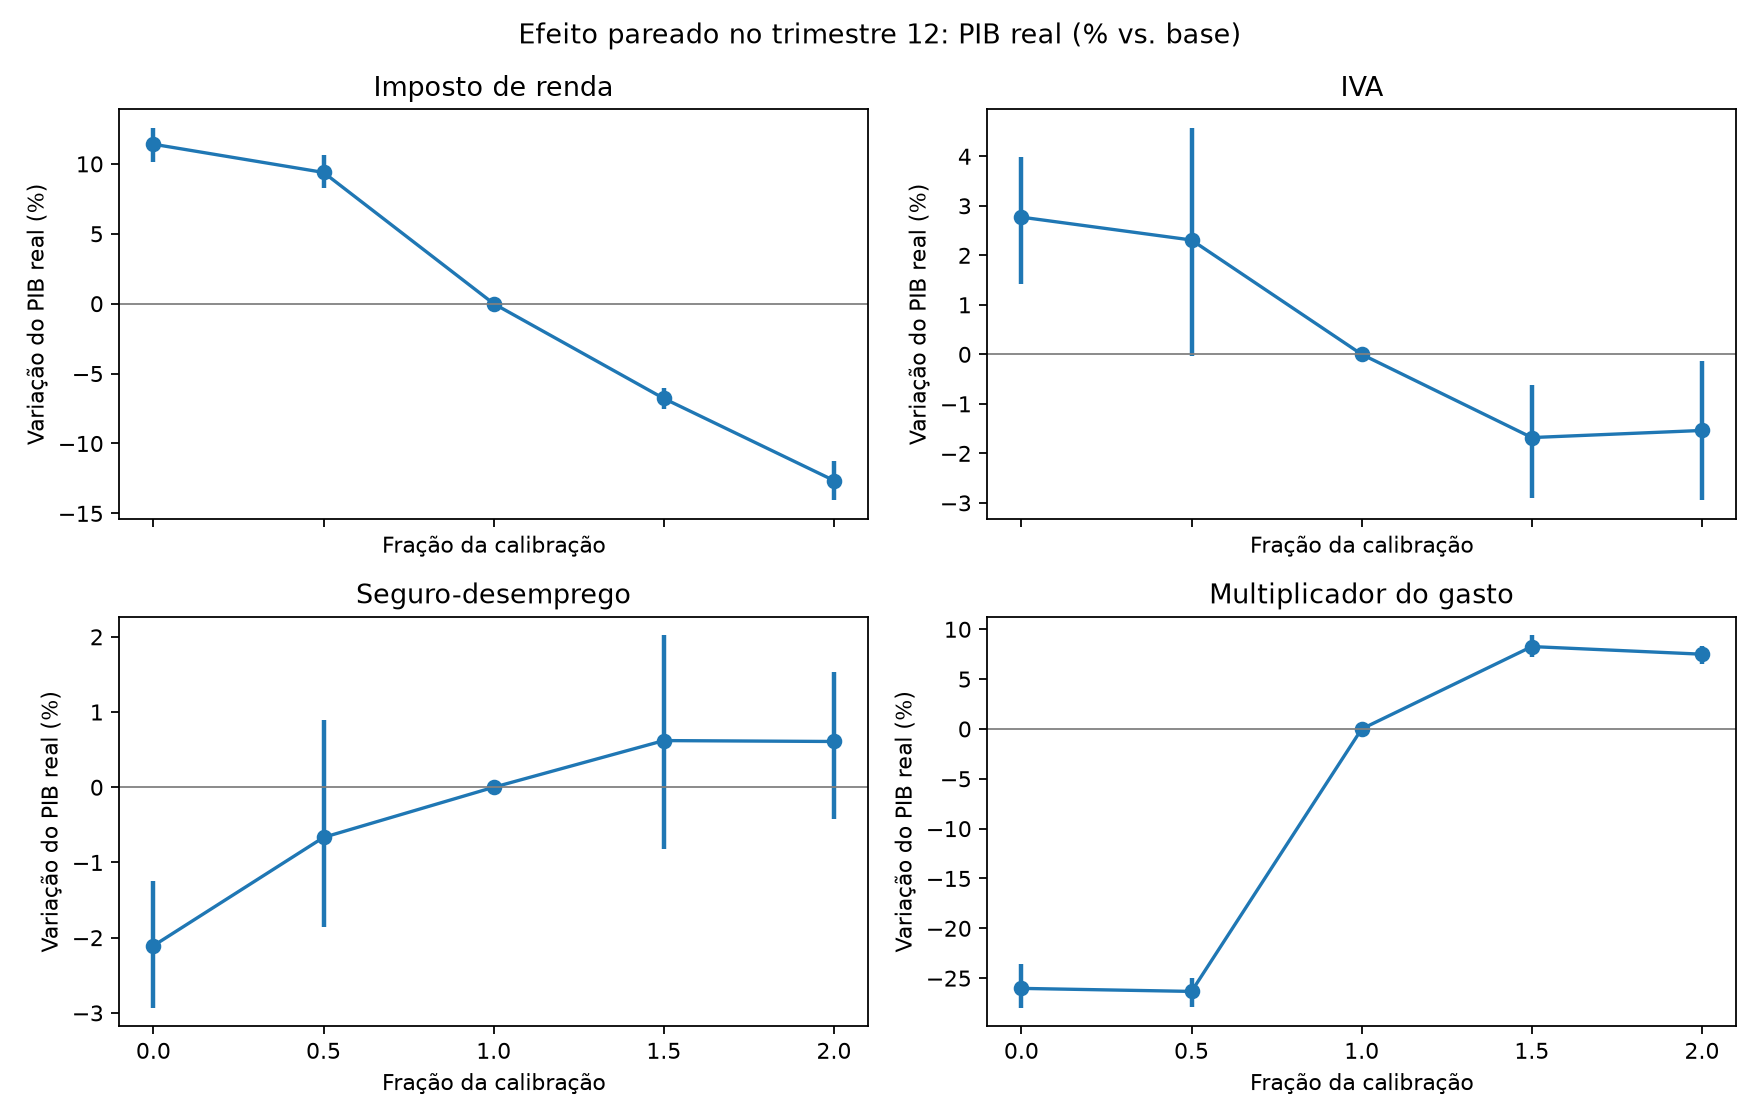

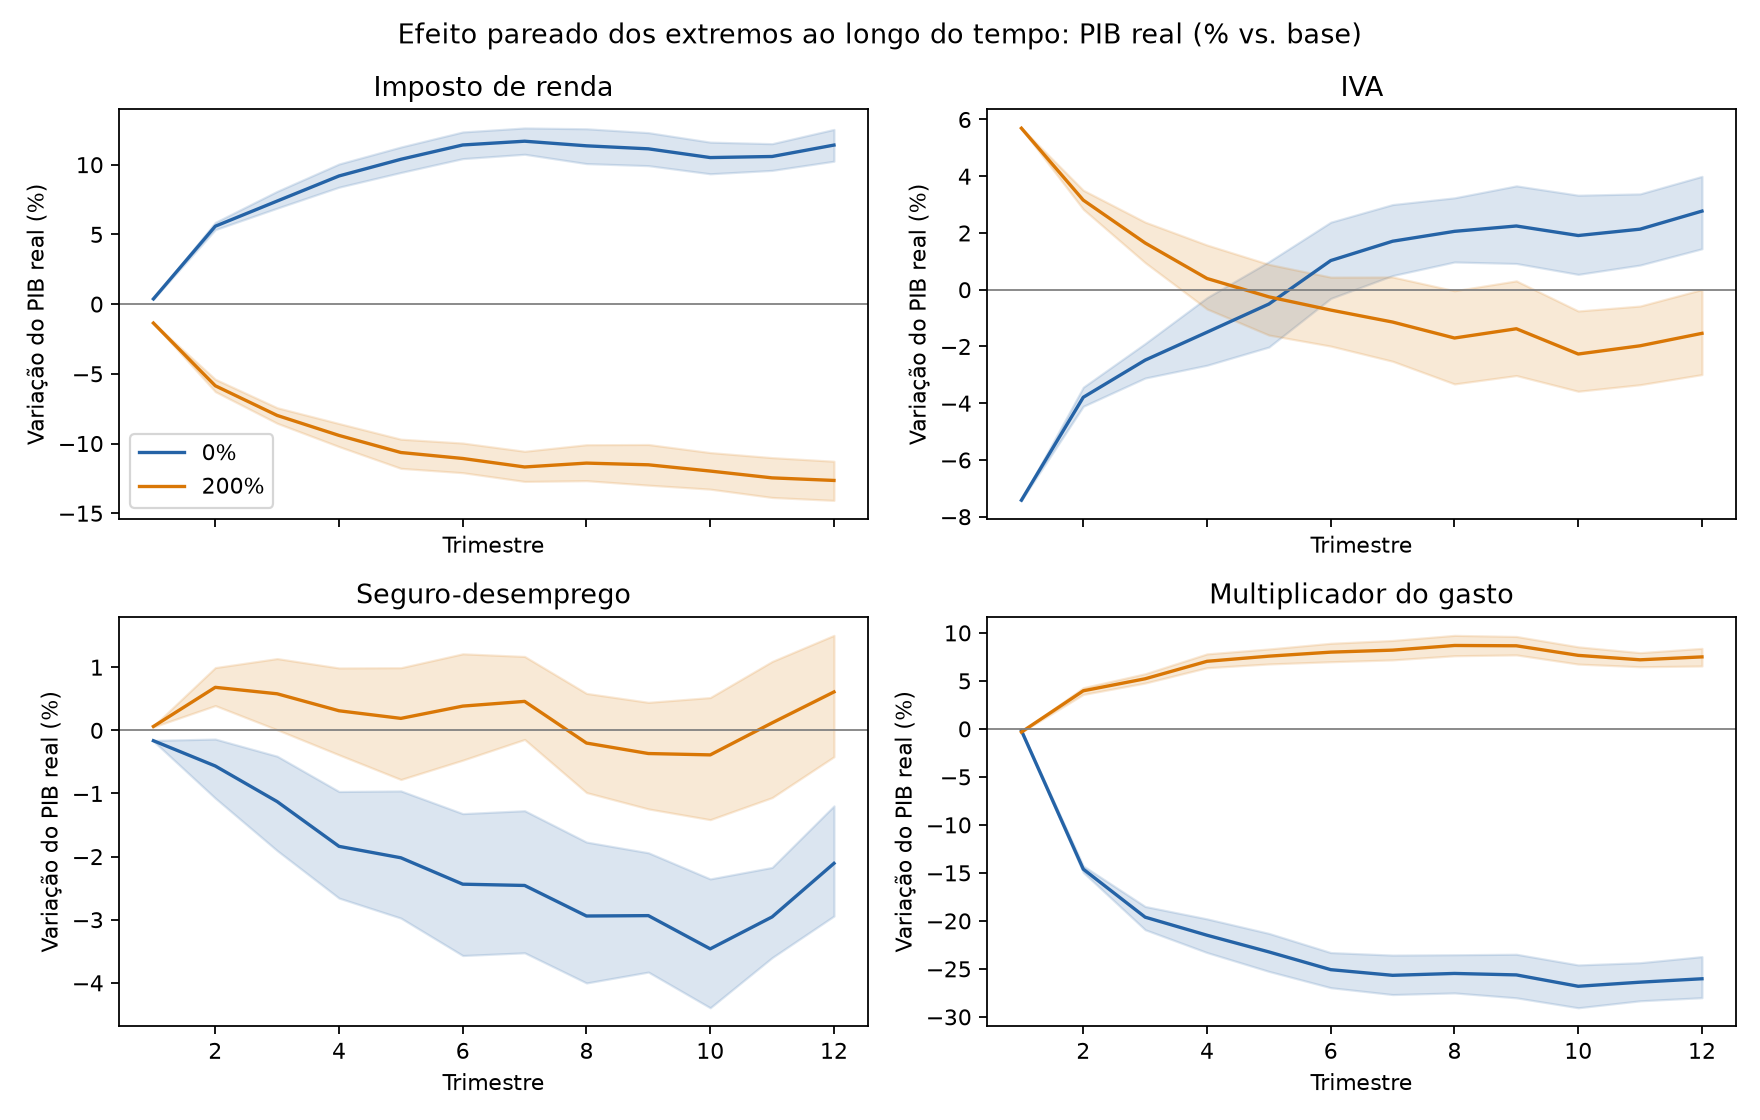

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, policy in zip(axes.flat, POLICIES):
    focus = effects.loc[effects.parameter.eq(policy) & effects.metric.eq(FOCUS_METRIC)]
    by_factor = focus.set_index("factor")
    x = [0, 0.5, 1, 1.5, 2]
    y = [0 if factor == 1 else by_factor.loc[factor, "mean_difference"] for factor in x]
    ax.plot(x, y, "o-")
    ax.vlines(focus.factor, focus.ci_low, focus.ci_high, linewidth=2)
    ax.axhline(0, color="0.5", linewidth=0.8)
    ax.set(title=POLICY_LABELS[policy], xticks=x,
           xlabel="Fração da calibração", ylabel=EFFECT_LABELS[FOCUS_METRIC])
fig.suptitle(f"Efeito pareado no trimestre {horizon}: {METRIC_LABELS[FOCUS_METRIC]}")
fig.tight_layout()
fig.savefig(output / f"paired_q12_{FOCUS_METRIC}.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, policy in zip(axes.flat, POLICIES):
    for level, color in (("low", "#2563a6"), ("high", "#d97706")):
        values = paired[(policy, level)][FOCUS_METRIC].unstack("quarter").to_numpy()
        draw = rng.integers(0, n_seeds, size=(BOOTSTRAPS, n_seeds))
        boot_means = values[draw].mean(axis=1)
        ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5], axis=0)
        quarters = np.arange(1, horizon + 1)
        ax.plot(quarters, values.mean(axis=0), color=color, label="0%" if level == "low" else "200%")
        ax.fill_between(quarters, ci_low, ci_high, color=color, alpha=0.16)
    ax.axhline(0, color="0.5", linewidth=0.8)
    ax.set(title=POLICY_LABELS[policy], xlabel="Trimestre",
           ylabel=EFFECT_LABELS[FOCUS_METRIC])
axes.flat[0].legend()
fig.suptitle(f"Efeito pareado dos extremos ao longo do tempo: {METRIC_LABELS[FOCUS_METRIC]}")
fig.tight_layout()
fig.savefig(output / f"paired_trajectory_{FOCUS_METRIC}.png", dpi=160)
plt.show()

## 3. Triagem global dos pontos LHS

Use somente as configurações `lhs`: elas espalham cada entrada no intervalo completo, com embaralhamento independente entre variáveis. Para o PIB real, converta cada média para **variação percentual frente à média da política base no mesmo trimestre**. Essa transformação não muda o Spearman, mas deixa os mapas de resposta em porcentagem. O coeficiente mede associação marginal monotônica. Um coeficiente próximo de zero **não exclui** resposta em U, limiares ou interações. O bootstrap abaixo reamostra políticas, não sementes. Se um indicador for constante em um trimestre, sua correlação fica indefinida (`NaN`); isso ocorre com o desemprego no trimestre 1.

In [12]:
lhs_configs = configs.loc[configs.kind.eq("lhs"), ["configuration_id", *POLICIES]]
lhs_q12 = summary.loc[summary.quarter.eq(horizon)].merge(
    lhs_configs, on="configuration_id", how="inner", validate="one_to_one")
assert len(lhs_q12) == n_configs - 9
lhs_q12["real_gdp_mean"] = 100 * (lhs_q12.real_gdp_mean / baseline_gdp_mean.loc[horizon] - 1)

rho = pd.DataFrame(index=METRICS, columns=POLICIES, dtype=float)
for metric in METRICS:
    for policy in POLICIES:
        rho.loc[metric, policy] = lhs_q12[policy].corr(
            lhs_q12[f"{metric}_mean"], method="spearman")
rho.index.name = "metric"
rho.to_csv(output / "lhs_spearman_q12.csv")
display(rho.round(3))

global_rows = []
y = lhs_q12[f"{FOCUS_METRIC}_mean"].to_numpy()
for policy in POLICIES:
    x = lhs_q12[policy].to_numpy()
    draw = rng.integers(0, len(lhs_q12), size=(BOOTSTRAPS, len(lhs_q12)))
    boot = [pd.Series(x[idx]).corr(pd.Series(y[idx]), method="spearman") for idx in draw]
    low, high = np.percentile(boot, [2.5, 97.5])
    global_rows.append({"parameter": policy, "metric": FOCUS_METRIC,
                        "spearman_rho": rho.loc[FOCUS_METRIC, policy],
                        "ci_low": low, "ci_high": high, "n_policies": len(lhs_q12)})
global_focus = pd.DataFrame(global_rows).sort_values("spearman_rho", key=abs, ascending=False)
global_focus.to_csv(output / f"lhs_spearman_q12_{FOCUS_METRIC}_bootstrap.csv", index=False)
display(global_focus)

,tau_INC,tau_VAT,theta_UB,spending_multiplier
metric,,,,
real_gdp,-0.347,0.035,0.106,0.798
real_household_consumption,-0.545,-0.020,0.140,-0.643
real_capitalformation,-0.467,-0.275,0.100,0.713
unemployment_rate,0.199,0.227,-0.080,-0.844
gdp_deflator_inflation,-0.038,0.015,-0.063,0.049
government_revenue,0.585,0.299,0.091,0.650
government_debt,-0.253,-0.235,0.078,0.895
debt_to_gdp,-0.187,-0.408,0.035,0.831
planned_government_consumption,0.057,-0.032,0.016,1.000


,parameter,metric,spearman_rho,ci_low,ci_high,n_policies
3,spending_multiplier,real_gdp,0.797650,0.768772,0.820428,491
0,tau_INC,real_gdp,-0.346644,-0.422439,-0.266394,491
2,theta_UB,real_gdp,0.105562,0.017123,0.191607,491
1,tau_VAT,real_gdp,0.034751,-0.051501,0.122769,491


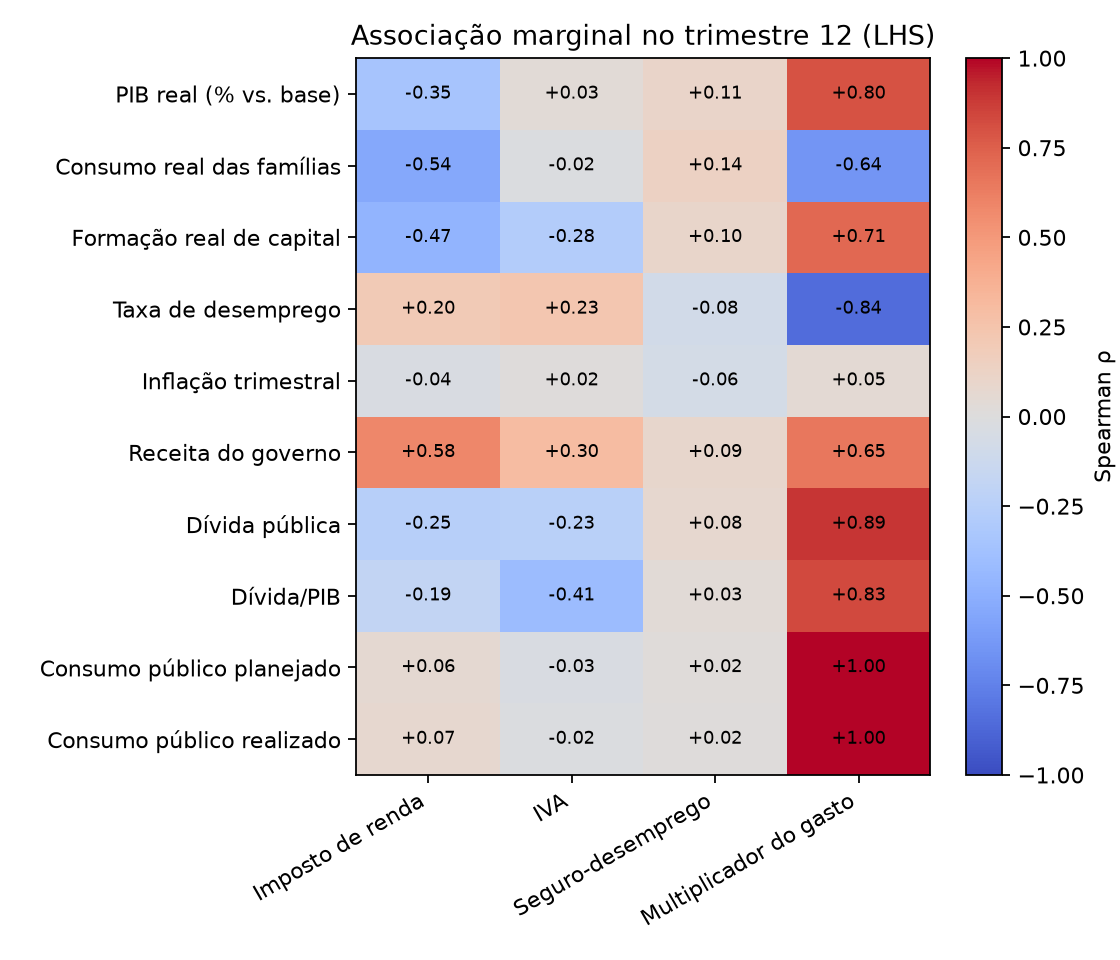

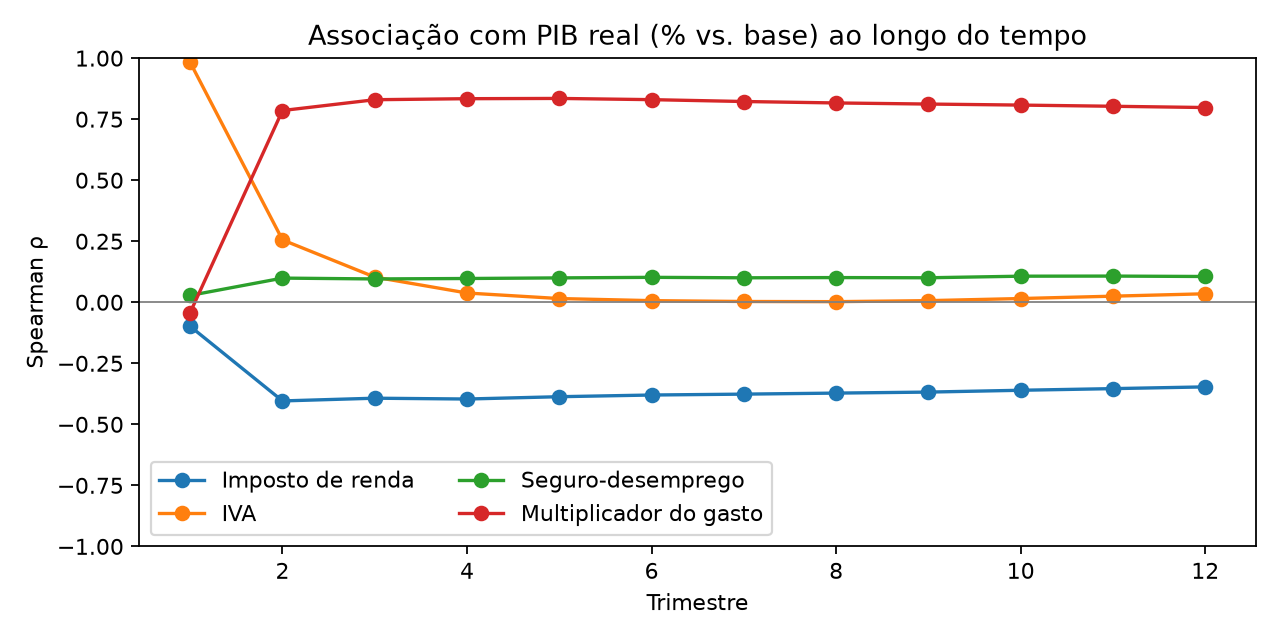

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(rho.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(POLICIES)), [POLICY_LABELS[p] for p in POLICIES], rotation=30, ha="right")
ax.set_yticks(range(len(METRICS)), [METRIC_LABELS[m] for m in METRICS])
for i in range(len(METRICS)):
    for j in range(len(POLICIES)):
        ax.text(j, i, f"{rho.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title(f"Associação marginal no trimestre {horizon} (LHS)")
fig.tight_layout()
fig.savefig(output / "lhs_spearman_q12.png", dpi=160)
plt.show()

lhs_by_quarter = summary.merge(lhs_configs, on="configuration_id", how="inner", validate="many_to_one")
lhs_by_quarter["real_gdp_mean"] = 100 * (
    lhs_by_quarter.real_gdp_mean / lhs_by_quarter.quarter.map(baseline_gdp_mean) - 1)
rho_rows = []
for quarter, frame in lhs_by_quarter.groupby("quarter"):
    for metric in METRICS:
        response = frame[f"{metric}_mean"]
        for policy in POLICIES:
            correlation = np.nan if response.nunique() < 2 else frame[policy].corr(response, method="spearman")
            rho_rows.append({"quarter": quarter, "metric": metric, "parameter": policy,
                             "spearman_rho": correlation})
rho_time = pd.DataFrame(rho_rows)
rho_time.to_csv(output / "lhs_spearman_by_quarter.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
for policy in POLICIES:
    line = rho_time.loc[rho_time.metric.eq(FOCUS_METRIC) & rho_time.parameter.eq(policy)]
    ax.plot(line.quarter, line.spearman_rho, marker="o", label=POLICY_LABELS[policy])
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set(xlabel="Trimestre", ylabel="Spearman ρ", ylim=(-1, 1),
       title=f"Associação com {METRIC_LABELS[FOCUS_METRIC]} ao longo do tempo")
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(output / f"lhs_spearman_trajectory_{FOCUS_METRIC}.png", dpi=160)
plt.show()

## 4. Padrões conjuntos com o multiplicador de gasto

Cada mapa agrupa os 491 pontos LHS em cinco faixas por eixo e mostra a média do indicador no trimestre 12. Os outros dois parâmetros variam dentro de cada célula. Esses mapas ajudam a localizar mudanças de regime e possíveis interações, mas não isolam uma interação nem substituem uma experiência fatorial dedicada. Confira o número mínimo de políticas por célula antes de interpretar cores isoladas.

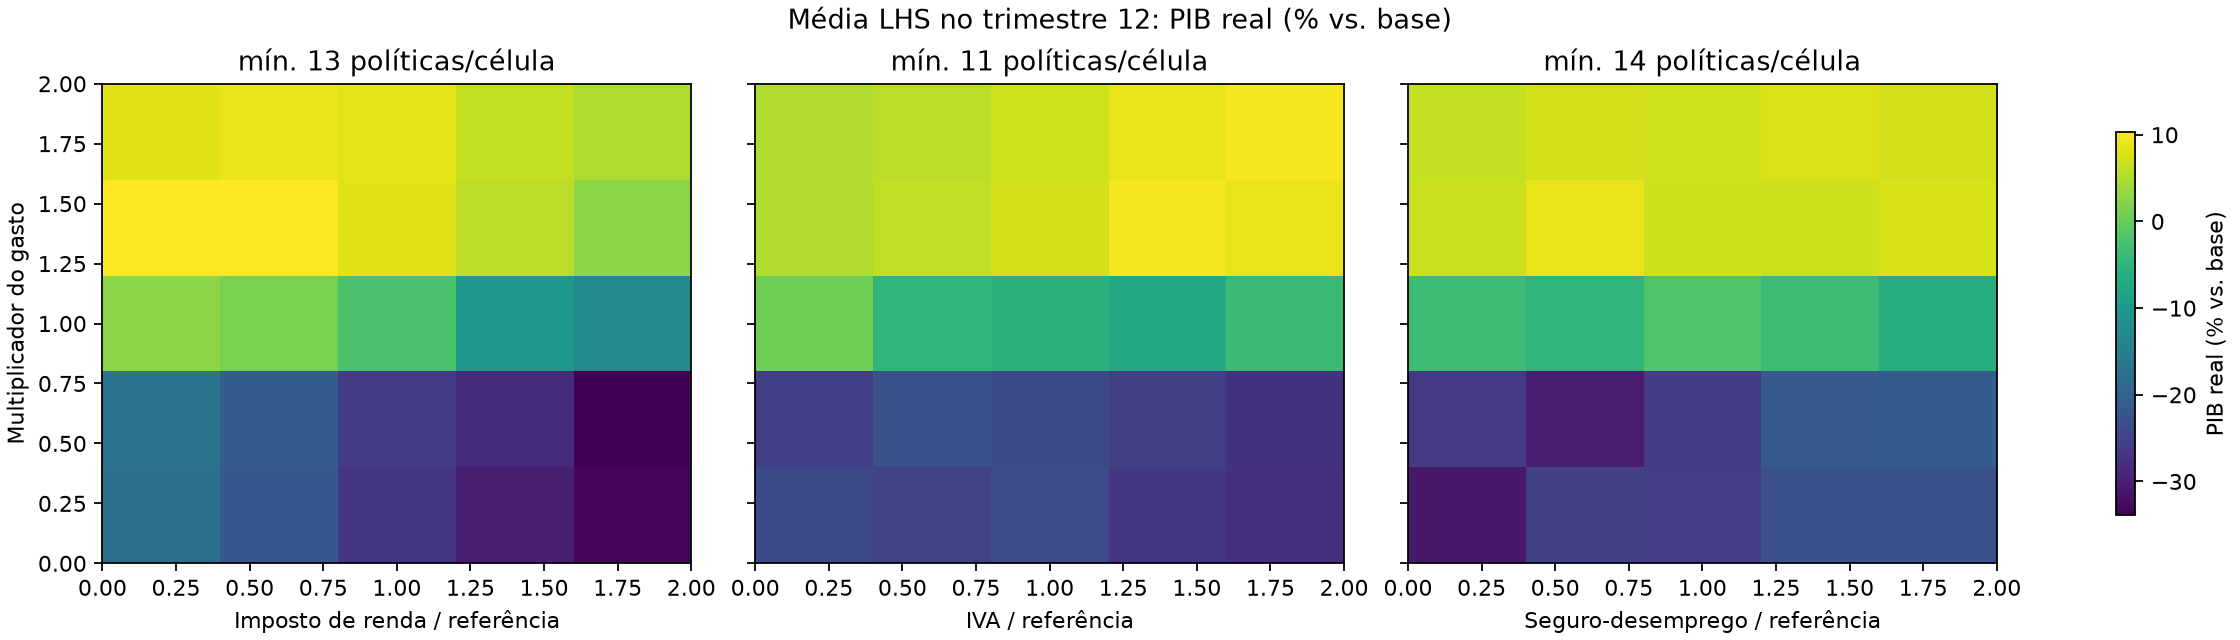

Arquivos salvos em /Users/danielbandrade/Documents/programing/BeforeIT-dba/dba-studies/machine-learning/fiscal-policy-dataset/experiments/austria-scale-0.001-zero-to-double-expanded/sensitivity


In [14]:
edges = np.linspace(0, 2, 6)
maps = []
for policy in POLICIES[:3]:
    x = lhs_q12[policy] / metadata["policy"][policy]["baseline"]
    y = lhs_q12["spending_multiplier"]
    frame = pd.DataFrame({
        "x_bin": pd.cut(x, edges, labels=False, include_lowest=True),
        "y_bin": pd.cut(y, edges, labels=False, include_lowest=True),
        "response": lhs_q12[f"{FOCUS_METRIC}_mean"],
    })
    grouped = frame.groupby(["y_bin", "x_bin"], observed=True).response.agg(["mean", "count"])
    means = grouped["mean"].unstack("x_bin").reindex(index=range(5), columns=range(5))
    counts = grouped["count"].unstack("x_bin").reindex(index=range(5), columns=range(5), fill_value=0)
    maps.append((policy, means.to_numpy(), counts.to_numpy()))
vmin = min(np.nanmin(means) for _, means, _ in maps)
vmax = max(np.nanmax(means) for _, means, _ in maps)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True, constrained_layout=True)
for ax, (policy, means, counts) in zip(axes, maps):
    image = ax.imshow(means, origin="lower", aspect="auto", extent=[0, 2, 0, 2], vmin=vmin, vmax=vmax)
    ax.set(xlabel=f"{POLICY_LABELS[policy]} / referência",
           title=f"mín. {counts.min()} políticas/célula")
axes[0].set_ylabel("Multiplicador do gasto")
fig.colorbar(image, ax=axes, label=METRIC_LABELS[FOCUS_METRIC], shrink=0.8)
fig.suptitle(f"Média LHS no trimestre {horizon}: {METRIC_LABELS[FOCUS_METRIC]}")
fig.savefig(output / f"lhs_pairwise_{FOCUS_METRIC}.png", dpi=160)
plt.show()
print("Arquivos salvos em", output)

## Como ler os resultados

- **Diferença pareada:** resposta à mudança de um parâmetro com os outros na calibração; a faixa é a incerteza entre as sementes comuns.
- **Spearman LHS:** associação marginal no domínio inteiro; não converta `ρ` em porcentagem de variância explicada.
- **Mapas bivariados:** médias sobre os outros dois parâmetros; células pouco povoadas podem oscilar por amostragem.
- A calibração e a escala `0.001` são fixas. O domínio de 0 a 2 vezes a referência inclui políticas extremas, sobretudo no gasto planejado. Valide conclusões econômicas fora da simulação antes de aplicá-las.